# Mushroom Classification: Edible or Poisonous?
**Information Systems — Group Project**

## 1. Introduction
This project investigates whether observable mushroom characteristics can predict whether a mushroom is edible or poisonous. We compare an entropy-based Decision Tree with K-Nearest Neighbours (KNN), examine informative features, and evaluate the effect of model complexity on generalisation.

Research questions:
- Which categorical characteristics provide the most information about mushroom class?
- How does tree depth affect training and validation performance?
- How do Decision Tree and KNN compare on unseen observations?
- How frequently are poisonous mushrooms incorrectly classified as edible?

This is an educational classification experiment, not a tool for deciding whether wild mushrooms are safe to eat.

## 2. Library imports
Import packages for data manipulation, visualisation, preprocessing and model evaluation. A fixed random seed makes the data split reproducible.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (mutual_info_score, accuracy_score, recall_score,
                             classification_report, ConfusionMatrixDisplay, confusion_matrix,
                             make_scorer, f1_score)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

SEED = 42

In [4]:
from pathlib import Path
from time import perf_counter
from sklearn.metrics import precision_score, fbeta_score, precision_recall_curve, roc_curve, roc_auc_score, average_precision_score
from sklearn.model_selection import cross_val_predict
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder
from sklearn.inspection import permutation_importance
from scipy.stats import chi2_contingency
OUT = Path('report_outputs'); OUT.mkdir(exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(OUT / (name + '.png'), dpi=200, bbox_inches='tight'); plt.show()
def table(data, name):
    display(data); data.to_csv(OUT / (name + '.csv'))


## 3. Data understanding
Load the semicolon-separated dataset and inspect its dimensions, data types and numerical summaries. The target `class` uses `e` for edible and `p` for poisonous.

In [5]:
df = pd.read_csv("secondary_data.csv", sep=";")
print("Dataset shape:", df.shape)
display(df.head())
df.info()
display(df.describe())
display(df["class"].value_counts(dropna=False))

Dataset shape: (61069, 21)


,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-height,...,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
0,p,15.26,x,g,o,f,e,NaN,w,16.95,...,s,y,w,u,w,t,g,NaN,d,w
1,p,16.60,x,g,o,f,e,NaN,w,17.99,...,s,y,w,u,w,t,g,NaN,d,u
2,p,14.07,x,g,o,f,e,NaN,w,17.80,...,s,y,w,u,w,t,g,NaN,d,w
3,p,14.17,f,h,e,f,e,NaN,w,15.77,...,s,y,w,u,w,t,p,NaN,d,w
4,p,14.64,x,h,o,f,e,NaN,w,16.53,...,s,y,w,u,w,t,p,NaN,d,w


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61069 entries, 0 to 61068
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   class                 61069 non-null  object 
 1   cap-diameter          61069 non-null  float64
 2   cap-shape             61069 non-null  object 
 3   cap-surface           46949 non-null  object 
 4   cap-color             61069 non-null  object 
 5   does-bruise-or-bleed  61069 non-null  object 
 6   gill-attachment       51185 non-null  object 
 7   gill-spacing          36006 non-null  object 
 8   gill-color            61069 non-null  object 
 9   stem-height           61069 non-null  float64
 10  stem-width            61069 non-null  float64
 11  stem-root             9531 non-null   object 
 12  stem-surface          22945 non-null  object 
 13  stem-color            61069 non-null  object 
 14  veil-type             3177 non-null   object 
 15  veil-color         

,cap-diameter,stem-height,stem-width
count,61069.000000,61069.000000,61069.000000
mean,6.733854,6.581538,12.149410
std,5.264845,3.370017,10.035955
min,0.380000,0.000000,0.000000
25%,3.480000,4.640000,5.210000
50%,5.860000,5.950000,10.190000
75%,8.540000,7.740000,16.570000
max,62.340000,33.920000,103.910000


class
p    33888
e    27181
Name: count, dtype: int64

The secondary mushroom dataset contains simulated observations. Verify its source and feature definitions against the dataset documentation before writing the report. The results describe this dataset, not real-world mushroom safety.

## 4. Data cleaning
Check missing values and remove exact duplicates and invalid class labels. Keep other missing values for preprocessing. The 80% threshold is a practical choice, not a proven optimum.

,Missing count,Missing %
veil-type,57892,94.797688
spore-print-color,54715,89.595376
veil-color,53656,87.861272
stem-root,51538,84.393064
stem-surface,38124,62.427746
gill-spacing,25063,41.040462
cap-surface,14120,23.121387
gill-attachment,9884,16.184971
ring-type,2471,4.046243
cap-color,0,0.000000


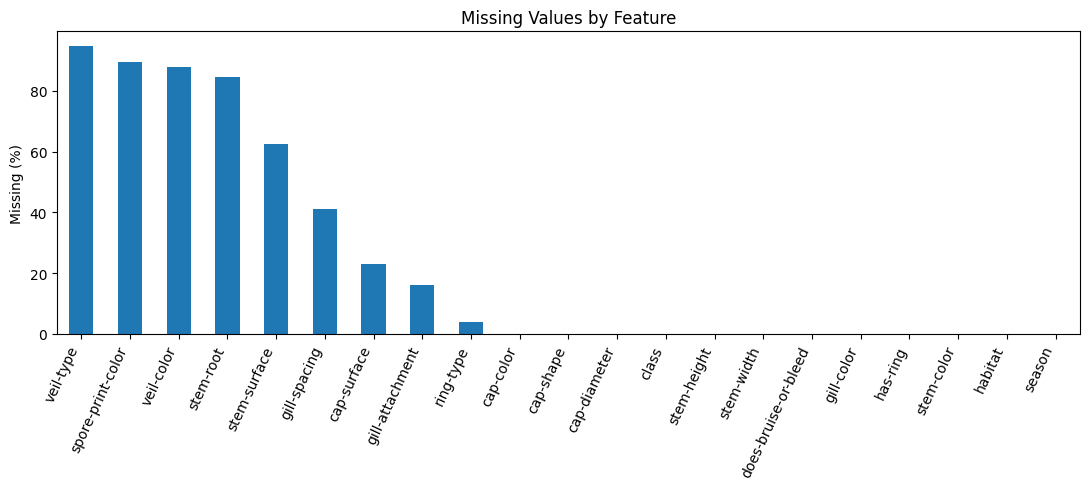

Exact duplicates: 146
Invalid or missing labels: 0
Cleaned shape: (60923, 21)


In [6]:
missing_summary = pd.DataFrame({"Missing count": df.isna().sum(),
                                "Missing %": df.isna().mean()*100}).sort_values("Missing %", ascending=False)
display(missing_summary)
missing_summary["Missing %"].plot.bar(figsize=(11,5))
plt.ylabel("Missing (%)")
plt.title("Missing Values by Feature")
plt.xticks(rotation=65, ha="right")
savefig("01_missing_values")
print("Exact duplicates:", df.duplicated().sum())
print("Invalid or missing labels:", (~df["class"].isin(["e", "p"])).sum())
df_clean = df.loc[df["class"].isin(["e", "p"])].drop_duplicates().copy()
print("Cleaned shape:", df_clean.shape)

In [7]:
table(missing_summary, 'missing_summary')
table(pd.DataFrame({'Rows':[len(df), len(df_clean), len(df)-len(df_clean)]}, index=['Original','Cleaned','Removed']), 'cleaning_summary')
display(df_clean.describe(include='all').T)


,Missing count,Missing %
veil-type,57892,94.797688
spore-print-color,54715,89.595376
veil-color,53656,87.861272
stem-root,51538,84.393064
stem-surface,38124,62.427746
gill-spacing,25063,41.040462
cap-surface,14120,23.121387
gill-attachment,9884,16.184971
ring-type,2471,4.046243
cap-color,0,0.000000


,Rows
Original,61069
Cleaned,60923
Removed,146


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
class,60923,2,p,33742,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cap-diameter,60923.0,NaN,NaN,NaN,6.741957,5.268435,0.38,3.49,5.88,8.55,62.34
cap-shape,60923,7,x,26932,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cap-surface,46803,11,t,8184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cap-color,60923,12,n,24205,NaN,NaN,NaN,NaN,NaN,NaN,NaN
does-bruise-or-bleed,60923,2,f,50333,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gill-attachment,51068,7,a,12697,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gill-spacing,35861,3,c,24682,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gill-color,60923,12,w,18492,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stem-height,60923.0,NaN,NaN,NaN,6.597202,3.358757,0.0,4.65,5.96,7.75,33.92


## 5. Data partitioning
Use 80% for training and 20% for final testing. Stratification keeps class proportions similar. All tuning uses training data only.

In [8]:
train_df, test_df = train_test_split(df_clean, test_size=0.2, random_state=SEED,
                                    stratify=df_clean["class"])
X_train = train_df.drop(columns="class")
X_test = test_df[X_train.columns]
y_train, y_test = train_df["class"], test_df["class"]
print("Training:", X_train.shape, "Test:", X_test.shape)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Training: (48738, 20) Test: (12185, 20)


In [9]:
display(pd.DataFrame({'Train':y_train.value_counts(normalize=True), 'Test':y_test.value_counts(normalize=True)}))
print('Features excluded based on training missingness:', X_train.columns[X_train.isna().mean() > .8].tolist())

,Train,Test
class,,
p,0.553839,0.553878
e,0.446161,0.446122


Features excluded based on training missingness: ['stem-root', 'veil-type', 'veil-color', 'spore-print-color']


## 6. Exploratory data analysis
### 6.1 Class distribution
Examine whether one class dominates the training dataset. Accuracy alone may conceal poor performance on an underrepresented class.

,Count,Percentage
class,,
Poisonous,26993,55.383889
Edible,21745,44.616111


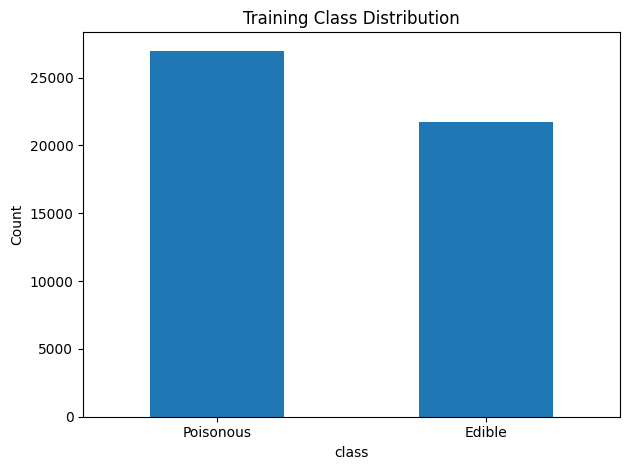

In [10]:
counts = y_train.value_counts().rename({"e":"Edible", "p":"Poisonous"})
display(pd.DataFrame({"Count":counts, "Percentage":100*counts/counts.sum()}))
counts.plot.bar(rot=0); plt.title("Training Class Distribution"); plt.ylabel("Count"); savefig("02_class_balance")

### 6.2 Cap shape and toxicity
Compare the proportion of poisonous mushrooms within each cap-shape category. Group counts are included because small categories may produce unstable percentages.

,size,Poisonous %
shape,,
Bell,4542,77.917217
Conical,1444,58.518006
Convex,21566,51.799128
Flat,10746,51.470315
Other,2646,75.396825
Spherical,2075,40.192771
Sunken,5719,53.820598


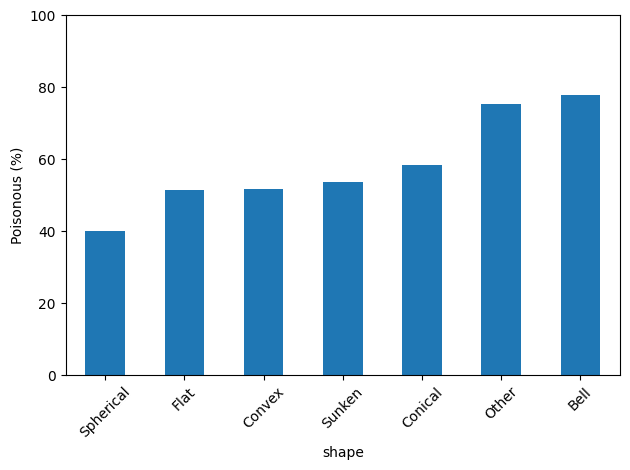

In [11]:
labels = {"b":"Bell", "c":"Conical", "x":"Convex", "f":"Flat", "s":"Sunken", "p":"Spherical", "o":"Other"}
shape = train_df["cap-shape"].map(labels).fillna(train_df["cap-shape"]).fillna("Missing")
summary = train_df.assign(shape=shape, poisonous=y_train.eq("p")).groupby("shape")["poisonous"].agg(["size","mean"])
summary["Poisonous %"] = 100*summary.pop("mean")
display(summary)
summary["Poisonous %"].sort_values().plot.bar(rot=45)
plt.ylabel("Poisonous (%)"); plt.ylim(0,100); plt.tight_layout(); plt.show()

### 6.3 Cap diameter and toxicity
Compare medians, variability and overlap using boxplots. Overlap would suggest that diameter alone is insufficient for reliable classification.

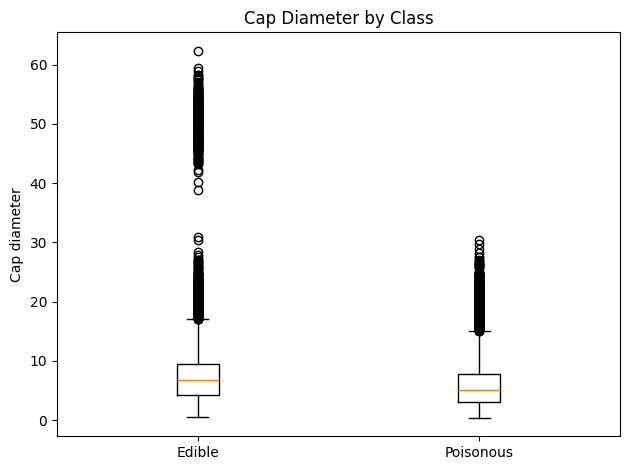

In [12]:
groups = [train_df.loc[y_train.eq(label), "cap-diameter"].dropna() for label in ["e","p"]]
plt.boxplot(groups); plt.xticks([1,2],["Edible","Poisonous"])
plt.ylabel("Cap diameter"); plt.title("Cap Diameter by Class"); savefig("04_cap_diameter")

### 6.4 Additional categorical charts
Compare class percentages within each category. Check sample counts before interpreting extreme percentages.

class,e,p
cap-shape,,
b,1003,3539
c,599,845
f,5215,5531
o,651,1995
p,1241,834
s,2641,3078
x,10395,11171


class,e,p
cap-color,,
b,781,200
e,702,2548
g,1834,1590
k,400,623
l,366,307
n,9920,9461
o,857,2055
p,364,994
r,167,1252


class,e,p
gill-color,,
b,557,189
e,210,624
f,1121,1600
g,1717,1561
k,753,1164
n,2392,5286
o,981,1334
p,1948,2836
r,436,690


class,e,p
stem-color,,
b,143,0
e,419,1215
f,0,720
g,1288,832
k,148,513
l,88,96
n,5815,8586
o,696,1050
p,103,721


class,e,p
habitat,,
d,16143,19163
g,1992,4350
h,549,1022
l,1536,981
m,1149,1192
p,0,285
u,97,0
w,279,0


class,e,p
season,,
a,10249,13894
s,1243,927
u,7701,10558
w,2552,1614


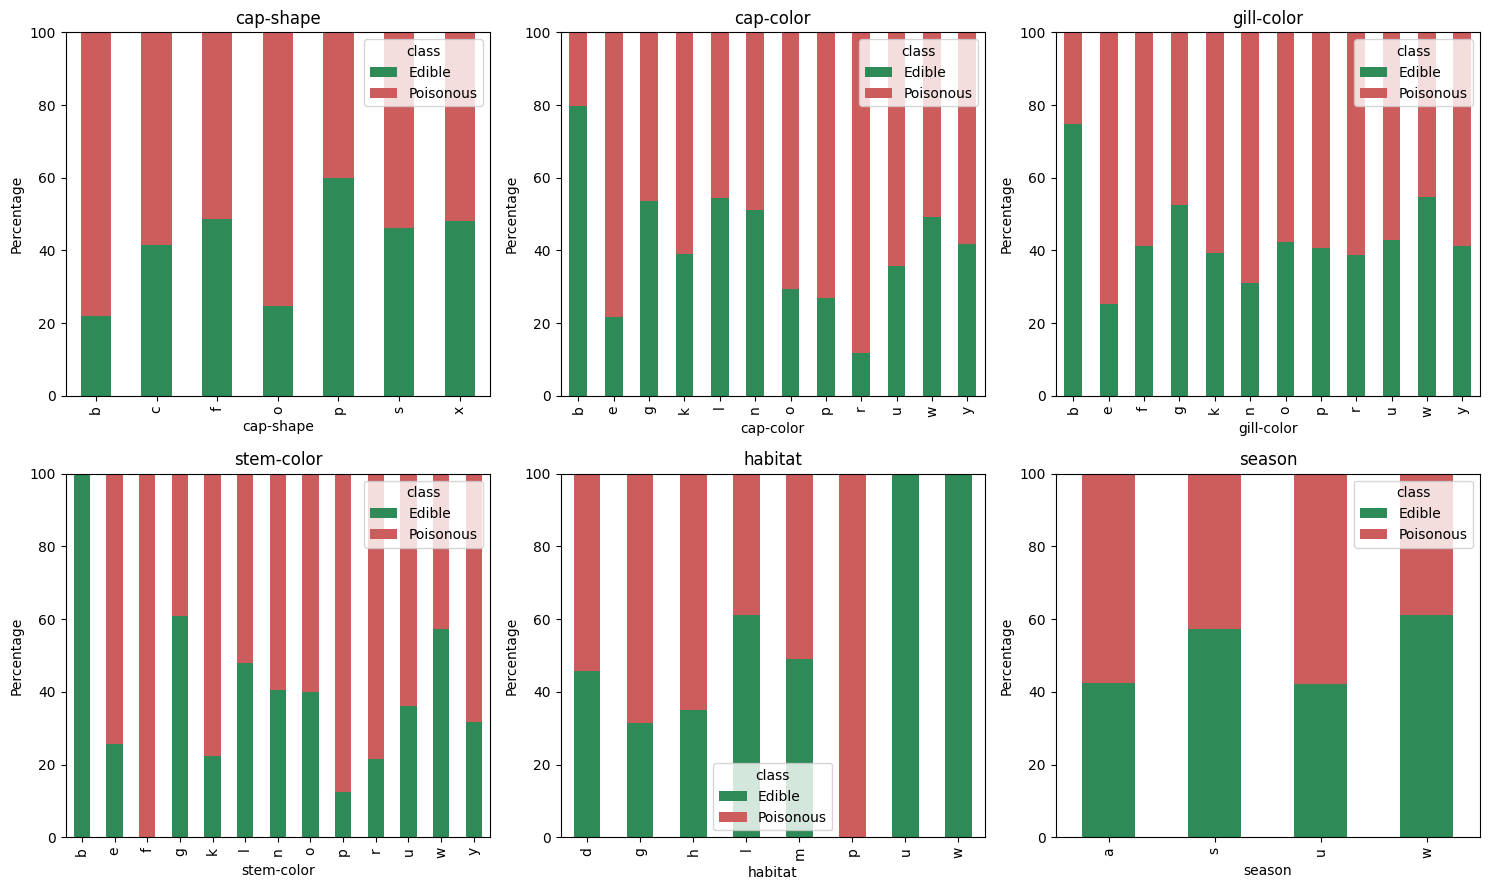

In [13]:
features = [f for f in ['cap-shape','cap-color','gill-color','stem-color','habitat','season'] if f in X_train]
fig, axes = plt.subplots(2,3,figsize=(15,9))
for ax,f in zip(axes.flat,features):
    counts = pd.crosstab(X_train[f].fillna('Missing'), y_train).reindex(columns=['e','p'],fill_value=0)
    table(counts, 'counts_'+f)
    (counts.div(counts.sum(axis=1),axis=0)*100).rename(columns={'e':'Edible','p':'Poisonous'}).plot.bar(stacked=True,ax=ax,color=['seagreen','indianred'])
    ax.set(title=f,ylabel='Percentage',ylim=(0,100))
for ax in list(axes.flat)[len(features):]: ax.set_visible(False)
savefig('05_category_percentages')

## 7. Information gain
Information gain measures the reduction in target entropy after observing a feature: $IG(Y,X)=H(Y)-H(Y|X)$. Mutual information is converted from natural-log units to bits. This analysis covers categorical features only and is descriptive; it does not select model inputs. High-cardinality features may receive inflated scores.

,Information gain (bits)
stem-surface,0.060762
stem-color,0.058537
cap-color,0.045086
cap-surface,0.043601
ring-type,0.041352
gill-attachment,0.035838
cap-shape,0.027279
gill-color,0.026700
habitat,0.026282
season,0.010276


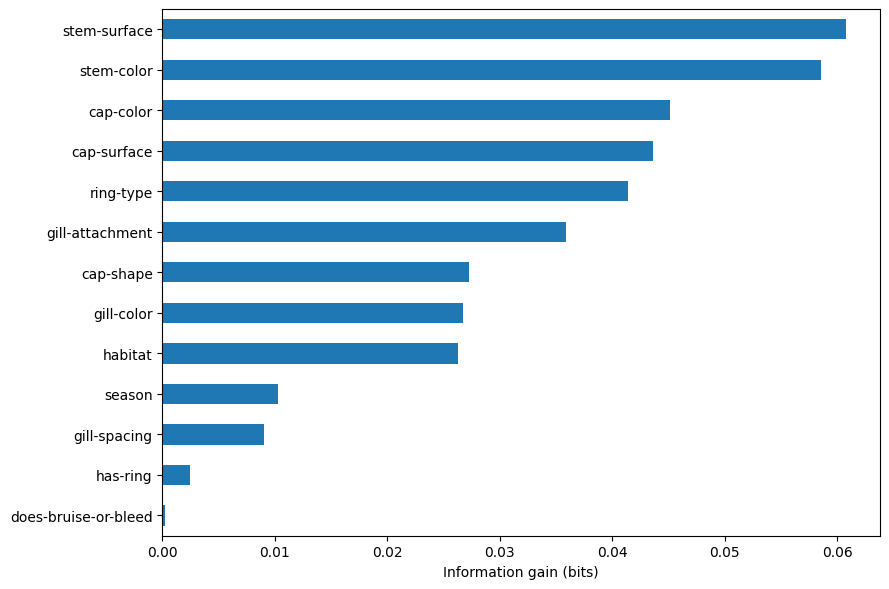

In [14]:
cat_cols = X_train.select_dtypes(exclude="number").columns
ig = pd.Series({col: mutual_info_score(X_train[col].fillna("Missing"), y_train)/np.log(2)
                for col in cat_cols if X_train[col].isna().mean() <= .8}).sort_values(ascending=False)
display(ig.to_frame("Information gain (bits)"))
ig.sort_values().plot.barh(figsize=(9,6)); plt.xlabel("Information gain (bits)"); plt.tight_layout(); savefig("06_information_gain")

### 7.1 All-feature mutual information (optional)
Information gain for categorical features is covered above. Mutual information also lets us examine numerical features. Higher values suggest stronger individual relationships with the class, not causation.

,MI (bits)
stem-width,0.092216
stem-height,0.064101
stem-surface,0.060762
stem-color,0.058537
cap-diameter,0.051556
cap-color,0.045086
cap-surface,0.043601
ring-type,0.041352
gill-attachment,0.035838
cap-shape,0.027279


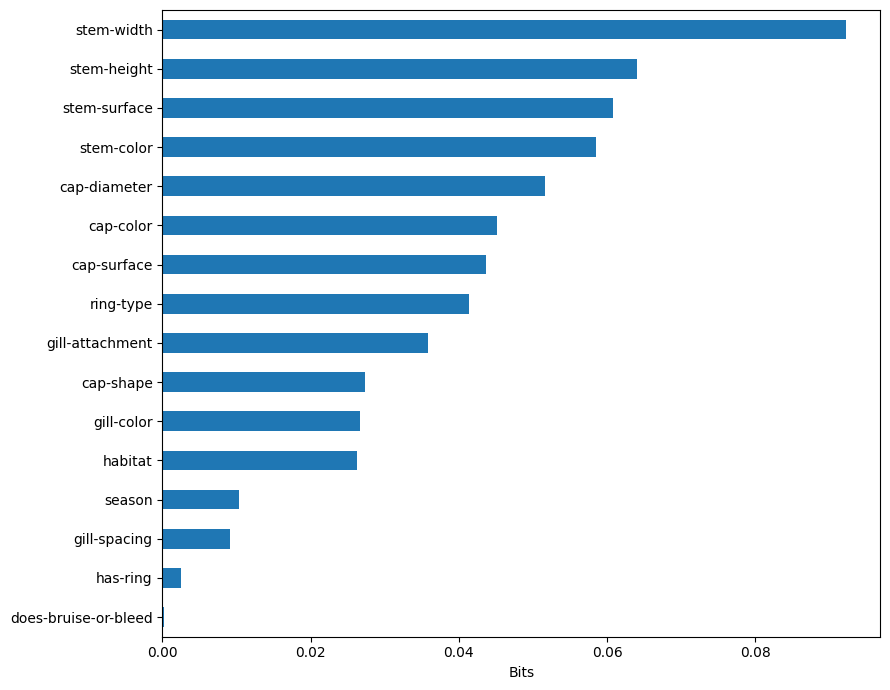

In [15]:
X_mi = X_train.loc[:,X_train.isna().mean() <= .8].copy()
cat = X_mi.select_dtypes(exclude='number').columns
num = X_mi.select_dtypes(include='number').columns
X_mi[num] = X_mi[num].fillna(X_mi[num].median())
if len(cat): X_mi[cat] = OrdinalEncoder().fit_transform(X_mi[cat].fillna('Missing'))
mi_ranking = pd.Series(mutual_info_classif(X_mi,y_train,discrete_features=X_mi.columns.isin(cat),random_state=SEED)/np.log(2),index=X_mi.columns).sort_values(ascending=False)
table(mi_ranking.to_frame('MI (bits)'), 'mutual_information')
mi_ranking.sort_values().plot.barh(figsize=(9,7)); plt.xlabel('Bits'); savefig('07_mutual_information')

### 7.2 Feature association heatmap (optional)
Cramér’s V measures how strongly two categorical features are related, from 0 to 1. Strong relationships may indicate overlapping information.

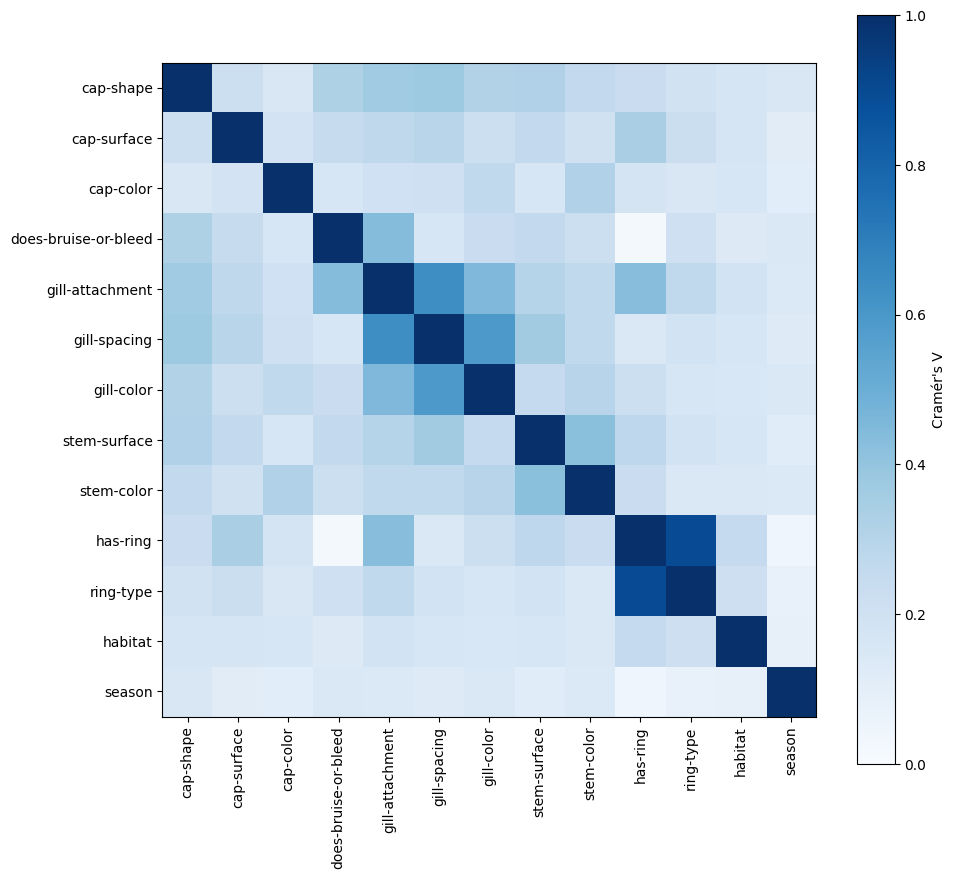

In [16]:
def cramers_v(x,y):
    t=pd.crosstab(x,y); r,k=t.shape
    return np.sqrt(chi2_contingency(t,correction=False)[0]/(t.values.sum()*min(r-1,k-1))) if min(r,k)>1 else 0
cdata=X_train[cat].fillna('Missing')
a=pd.DataFrame([[cramers_v(cdata[x],cdata[y]) for y in cat] for x in cat],index=cat,columns=cat)
fig,ax=plt.subplots(figsize=(10,9)); im=ax.imshow(a,vmin=0,vmax=1,cmap='Blues'); ax.set_xticks(range(len(cat)),cat,rotation=90); ax.set_yticks(range(len(cat)),cat); fig.colorbar(im,ax=ax,label="Cramér's V"); savefig('08_association_heatmap')

## 8. Preprocessing
Remove features with over 80% missing values within each training fold. Replace missing numerical values with the median and missing categories with a separate label. One-hot encoding converts categories to binary columns. KNN also scales numerical features because it uses distances.

In [17]:
def numeric_columns(X):
    return [col for col in X.select_dtypes(include="number") if X[col].isna().mean() <= .8]

def categorical_columns(X):
    return [col for col in X.select_dtypes(exclude="number") if X[col].isna().mean() <= .8]

def preprocessing(scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(steps), numeric_columns),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("encoder", OneHotEncoder(handle_unknown="ignore"))]), categorical_columns)
    ])

def tree(depth, weights=None, criterion="entropy"):
    return Pipeline([("preprocess", preprocessing()),
                     ("classifier", DecisionTreeClassifier(criterion=criterion, max_depth=depth,
                                                           class_weight=weights, random_state=SEED))])

def knn(k):
    return Pipeline([("preprocess", preprocessing(scale=True)),
                     ("classifier", KNeighborsClassifier(n_neighbors=k, n_jobs=-1))])

scoring = {"accuracy":"accuracy", "poisonous_recall":make_scorer(recall_score, pos_label="p"), "f2":make_scorer(fbeta_score,beta=2,pos_label="p",zero_division=0), "precision":make_scorer(precision_score,pos_label="p",zero_division=0)}

def tune(factory, values, parameter):
    rows = []
    for value in values:
        scores = cross_validate(factory(value), X_train, y_train, cv=cv,
                                scoring=scoring, return_train_score=True)
        rows.append({parameter:value, "Training accuracy":scores["train_accuracy"].mean(),
                     "Validation accuracy":scores["test_accuracy"].mean(),
                     "Validation SD":scores["test_accuracy"].std(),
                     "Poisonous recall":scores["test_poisonous_recall"].mean(), "F2":scores["test_f2"].mean(), "Precision":scores["test_precision"].mean(), "Fit seconds":scores["fit_time"].mean()})
    return pd.DataFrame(rows)

## 9. Decision Tree
### 9.1 Baseline
Use entropy as the splitting criterion and a maximum depth of five as an initial complexity constraint. Evaluate the baseline with five-fold cross-validation rather than using the test set.

In [18]:
baseline = cross_validate(tree(5), X_train, y_train, cv=cv, scoring=scoring)
print("Baseline validation accuracy:", baseline["test_accuracy"].mean())
print("Baseline poisonous recall:", baseline["test_poisonous_recall"].mean())

Baseline validation accuracy: 0.7253068471474805
Baseline poisonous recall: 0.6004149836044042


### 9.2 Tree depth and pre-pruning
Depth is the longest path of decisions, not the number of features. Test up to 40 and an unrestricted tree. Choose the smallest tested depth with the highest validation accuracy. A growing gap between training and validation accuracy suggests overfitting.

Unrestricted training depth: 24


,Depth,Training accuracy,Validation accuracy,Validation SD,Poisonous recall,F2,Precision,Fit seconds
0,1,0.608606,0.607883,0.003199,0.531620,0.557090,0.689385,0.154246
1,2,0.650688,0.650109,0.003191,0.525025,0.560690,0.770169,0.173453
2,3,0.679839,0.679101,0.004036,0.584300,0.615284,0.781255,0.189279
3,4,0.690770,0.689995,0.004171,0.526655,0.570797,0.859229,0.222620
4,5,0.725435,0.725307,0.003276,0.600415,0.638878,0.864249,0.262491
5,6,0.738397,0.737412,0.002523,0.627682,0.663490,0.861153,0.338540
6,7,0.753232,0.752780,0.002330,0.627978,0.667619,0.895260,0.311024
7,8,0.775263,0.773996,0.009109,0.948023,0.893655,0.727242,0.379854
8,9,0.793677,0.791333,0.006947,0.697107,0.730319,0.907559,0.334389
9,10,0.845957,0.845501,0.011532,0.744713,0.780687,0.969797,0.380431


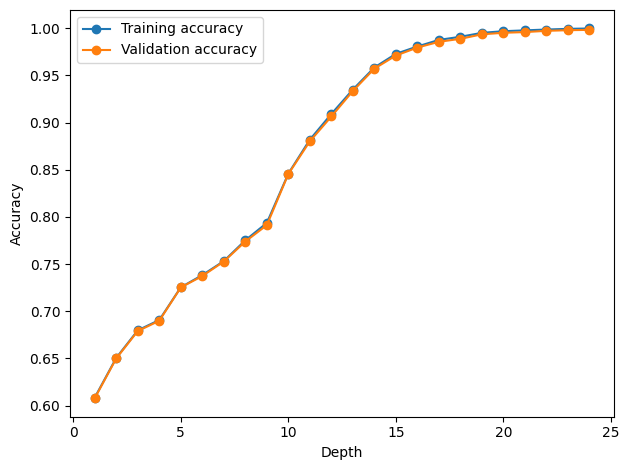

Selected depth: 24


In [19]:
unrestricted=tree(None).fit(X_train,y_train)
print('Unrestricted training depth:',unrestricted.named_steps['classifier'].get_depth())
tree_results=tune(tree,range(1,min(40,unrestricted.named_steps['classifier'].get_depth())+1),'Depth')
table(tree_results,'tree_depth')
tree_results.plot(x='Depth',y=['Training accuracy','Validation accuracy'],marker='o'); plt.ylabel('Accuracy'); savefig('09_tree_depth')
best_depth=int(tree_results.loc[tree_results['Validation accuracy'].idxmax(),'Depth'])
print('Selected depth:',best_depth)


### 9.3 Entropy versus Gini (optional)
Both criteria measure how mixed the classes are in a node. Compare them at the same selected depth to isolate the effect of the criterion. The main tree remains entropy-based.

In [20]:
criterion_results=tune(lambda c:tree(best_depth,criterion=c),['entropy','gini'],'Criterion'); table(criterion_results,'split_criteria')

,Criterion,Training accuracy,Validation accuracy,Validation SD,Poisonous recall,F2,Precision,Fit seconds
0,entropy,0.999759,0.998297,0.000322,0.998407,0.998429,0.998519,0.546469
1,gini,0.999692,0.997743,0.000853,0.997629,0.997762,0.998295,0.649101


## 10. K-Nearest Neighbours
KNN predicts the class using nearby training observations. Small k may be sensitive to noise, whereas large k may smooth away useful patterns. Compare candidate values using the same cross-validation folds as the Decision Tree. This may take several minutes for a large dataset. 

,k,Training accuracy,Validation accuracy,Validation SD,Poisonous recall,F2,Precision,Fit seconds
0,1,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.335541
1,3,0.999995,0.999979,0.000041,1.000000,0.999993,0.999963,0.481374
2,5,0.999979,0.999979,0.000041,1.000000,0.999993,0.999963,0.416275
3,11,0.999867,0.999774,0.000176,1.000000,0.999919,0.999593,0.451558
4,21,0.999687,0.999651,0.000154,0.999963,0.999852,0.999408,0.522442


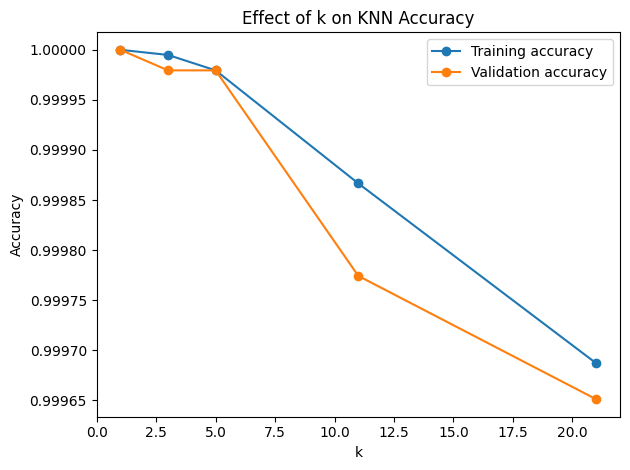

Selected k: 1


In [22]:
knn_results = tune(knn, [1, 3, 5, 11, 21], "k")

table(knn_results, "knn_tuning")

knn_results.plot(
    x="k",
    y=["Training accuracy", "Validation accuracy"],
    marker="o"
)

plt.ylabel("Accuracy")
plt.title("Effect of k on KNN Accuracy")
savefig("10_knn_tuning")

best_k = int(knn_results.loc[
    knn_results["Validation accuracy"].idxmax(), "k"
])

print("Selected k:", best_k)

## 11. Misclassification risk
Treat poisonous as the positive class. A false negative (poisonous predicted edible) is more consequential than a false positive (edible predicted poisonous). As an illustrative sensitivity experiment, compare Decision Trees assigning poisonous observations weights of 1, 2, 5 and 10. These weights are hypothetical, not measured real-world costs. Select the weighted alternative by validation poisonous recall, breaking ties by accuracy and then lower weight. This is separate from the accuracy-optimised baseline comparison.

In [23]:
risk_results = tune(lambda w: tree(best_depth, {"e":1,"p":w}), [1,2,5,10], "Poisonous weight")
table(risk_results,"class_weights")
best_weight = int(risk_results.sort_values(["F2","Poisonous recall","Poisonous weight"], ascending=[False,False,True]).iloc[0]["Poisonous weight"])
print("Selected weight:", best_weight)

,Poisonous weight,Training accuracy,Validation accuracy,Validation SD,Poisonous recall,F2,Precision,Fit seconds
0,1,0.999759,0.998297,0.000322,0.998407,0.998429,0.998519,0.788727
1,2,0.999903,0.998071,0.000300,0.998444,0.998370,0.998075,0.787161
2,5,1.000000,0.998748,0.000533,0.998889,0.998881,0.998851,0.680098
3,10,0.999995,0.998892,0.000327,0.999148,0.999089,0.998852,0.693379


Selected weight: 10


### 11.1 Threshold tuning (optional)
A lower threshold can catch more poisonous examples but may reject more edible ones. Select the threshold using out-of-fold training probabilities and F2, which gives recall more weight than precision. These validation results are used for tuning, not as independent final performance.

Selected threshold: 0.7096774193548387


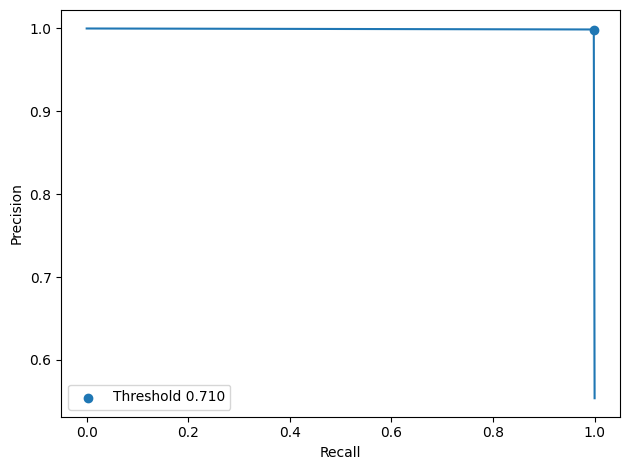

In [24]:
oof=cross_val_predict(tree(best_depth),X_train,y_train,cv=cv,method='predict_proba')[:,1]
p,r,t=precision_recall_curve(y_train,oof,pos_label='p')
f2=5*p[:-1]*r[:-1]/np.maximum(4*p[:-1]+r[:-1],1e-12)
i=int(np.argmax(f2)); best_threshold=float(t[i]); print('Selected threshold:',best_threshold)
plt.plot(r,p); plt.scatter(r[i],p[i],label=f'Threshold {best_threshold:.3f}'); plt.xlabel('Recall'); plt.ylabel('Precision'); plt.legend(); savefig('11_validation_PR')

## 12. Final model evaluation
Fit the selected configurations on all training data and evaluate them on the same held-out test set. Report accuracy, poisonous recall, poisonous F1 and both types of errors. Do not use these test results to retune the models.

In [25]:
models={'Decision Tree':tree(best_depth),'KNN':knn(best_k),'Risk-weighted Tree':tree(best_depth,{'e':1,'p':best_weight})}
predictions={}; probabilities={}; timings={}
for name,model in models.items():
    start=perf_counter(); model.fit(X_train,y_train); fit_time=perf_counter()-start
    start=perf_counter(); prob=model.predict_proba(X_test)[:,list(model.classes_).index('p')]; predict_time=perf_counter()-start
    probabilities[name]=prob; predictions[name]=model.predict(X_test); timings[name]=(fit_time,predict_time)
predictions['Threshold-tuned Tree']=np.where(probabilities['Decision Tree']>=best_threshold,'p','e')
rows=[]
for name,pred in predictions.items():
    tn,fp,fn,tp=confusion_matrix(y_test,pred,labels=['e','p']).ravel()
    rows.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Precision':precision_score(y_test,pred,pos_label='p',zero_division=0),'Recall':recall_score(y_test,pred,pos_label='p'),'F1':f1_score(y_test,pred,pos_label='p'),'F2':fbeta_score(y_test,pred,beta=2,pos_label='p'),'False positives':fp,'False negatives':fn,'False negative rate':fn/(fn+tp)})
    print(name); print(classification_report(y_test,pred,zero_division=0))
comparison=pd.DataFrame(rows).set_index('Model'); table(comparison,'test_metrics')
table(pd.DataFrame(timings,index=['Fit seconds','Probability prediction seconds']).T,'runtime')


Decision Tree
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      5436
           p       1.00      1.00      1.00      6749

    accuracy                           1.00     12185
   macro avg       1.00      1.00      1.00     12185
weighted avg       1.00      1.00      1.00     12185

KNN
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      5436
           p       1.00      1.00      1.00      6749

    accuracy                           1.00     12185
   macro avg       1.00      1.00      1.00     12185
weighted avg       1.00      1.00      1.00     12185

Risk-weighted Tree
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      5436
           p       1.00      1.00      1.00      6749

    accuracy                           1.00     12185
   macro avg       1.00      1.00      1.00     12185
weighted avg       1.00      1.00    

,Accuracy,Precision,Recall,F1,F2,False positives,False negatives,False negative rate
Model,,,,,,,,
Decision Tree,0.999343,0.999407,0.999407,0.999407,0.999407,4,4,0.000593
KNN,1.000000,1.000000,1.000000,1.000000,1.000000,0,0,0.000000
Risk-weighted Tree,0.999508,0.999555,0.999555,0.999555,0.999555,3,3,0.000445
Threshold-tuned Tree,0.999343,0.999407,0.999407,0.999407,0.999407,4,4,0.000593


,Fit seconds,Probability prediction seconds
Decision Tree,0.914222,0.035080
KNN,0.227623,11.699760
Risk-weighted Tree,0.803451,0.042855


### 12.1 Confusion matrices
Rows are actual classes and columns are predicted classes. The lower-left cell is the number of poisonous observations predicted edible. Compare the two main models and the two risk experiments.

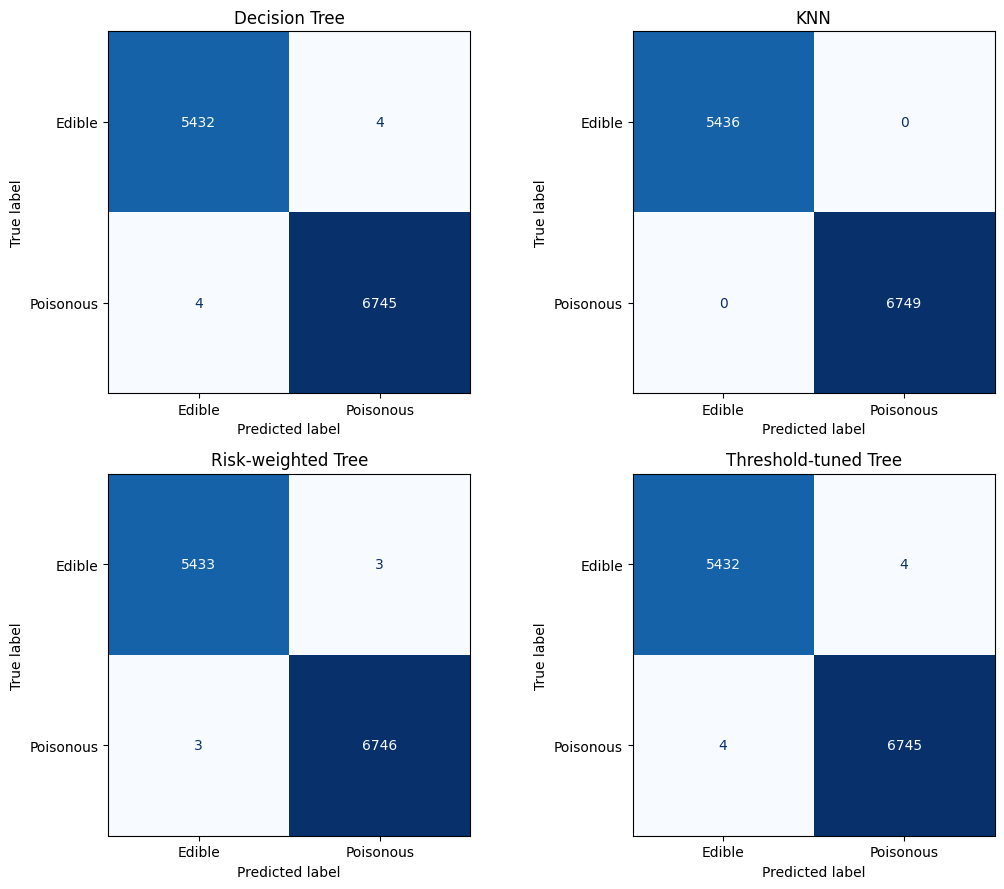

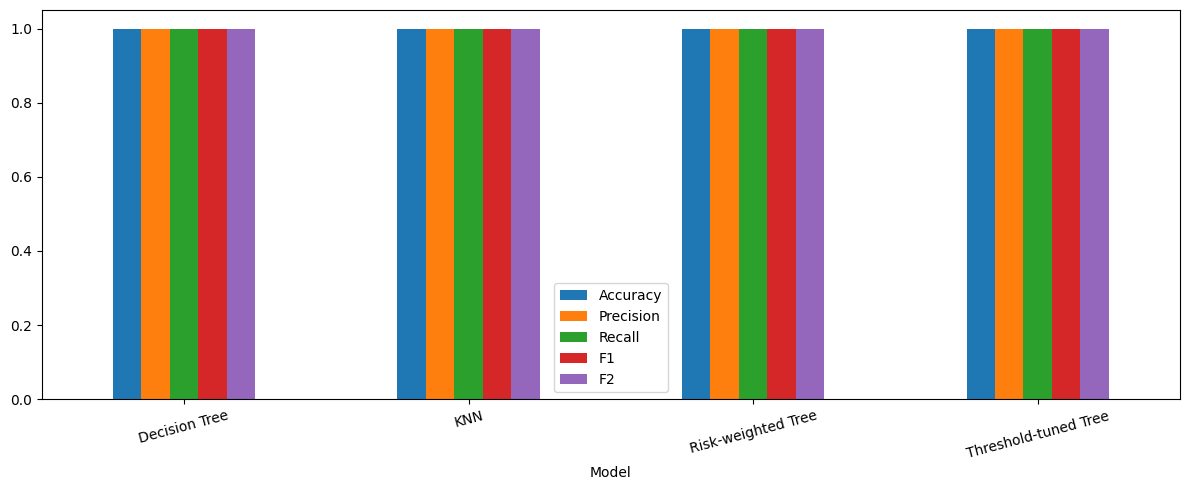

In [26]:
fig,axes=plt.subplots(2,2,figsize=(11,9))
for ax,(name,pred) in zip(axes.flat,predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=['e','p'],display_labels=['Edible','Poisonous'],ax=ax,colorbar=False,cmap='Blues'); ax.set_title(name)
savefig('12_confusion_matrices')
comparison[['Accuracy','Precision','Recall','F1','F2']].plot.bar(figsize=(12,5)); plt.ylim(0,1.05); plt.xticks(rotation=15); savefig('13_model_comparison')

### 12.2 ROC and precision-recall curves (optional)
ROC shows how well the model separates the classes across thresholds. Precision-recall focuses on the poisonous class. Threshold tuning does not create a new probability model, so its curve is the same as the ordinary tree.

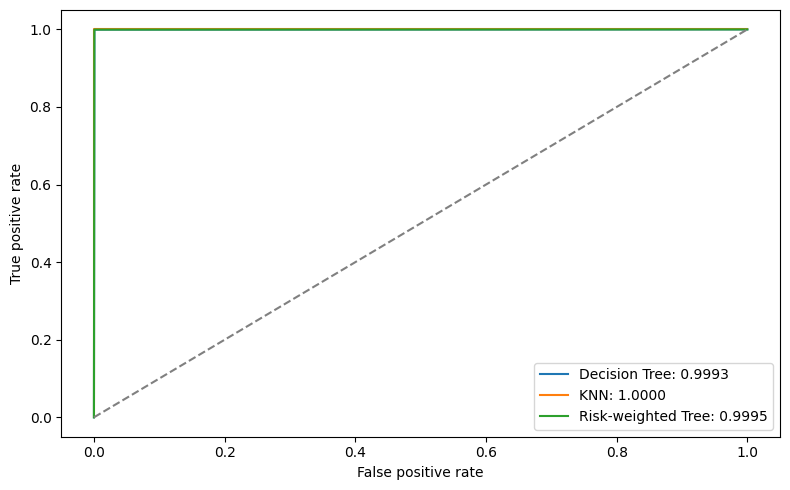

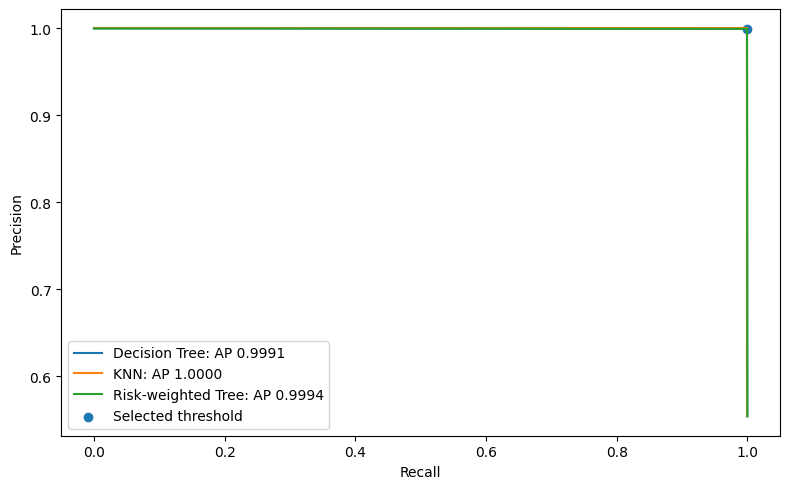

In [27]:
plt.figure(figsize=(8,5))
for name,prob in probabilities.items():
    fpr,tpr,_=roc_curve(y_test,prob,pos_label='p'); plt.plot(fpr,tpr,label=f'{name}: {roc_auc_score(y_test.eq("p"),prob):.4f}')
plt.plot([0,1],[0,1],'--',color='grey'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.legend(); savefig('14_ROC')
plt.figure(figsize=(8,5))
for name,prob in probabilities.items():
    p,r,_=precision_recall_curve(y_test,prob,pos_label='p'); plt.plot(r,p,label=f'{name}: AP {average_precision_score(y_test.eq("p"),prob):.4f}')
plt.scatter(comparison.loc['Threshold-tuned Tree','Recall'],comparison.loc['Threshold-tuned Tree','Precision'],label='Selected threshold'); plt.xlabel('Recall'); plt.ylabel('Precision'); plt.legend(); savefig('15_test_PR')

## 13. Model interpretation
### 13.1 Decision Tree diagram
Show the first three levels of the fitted tree. This is a partial view, not a separate shallow model or a mushroom identification guide.

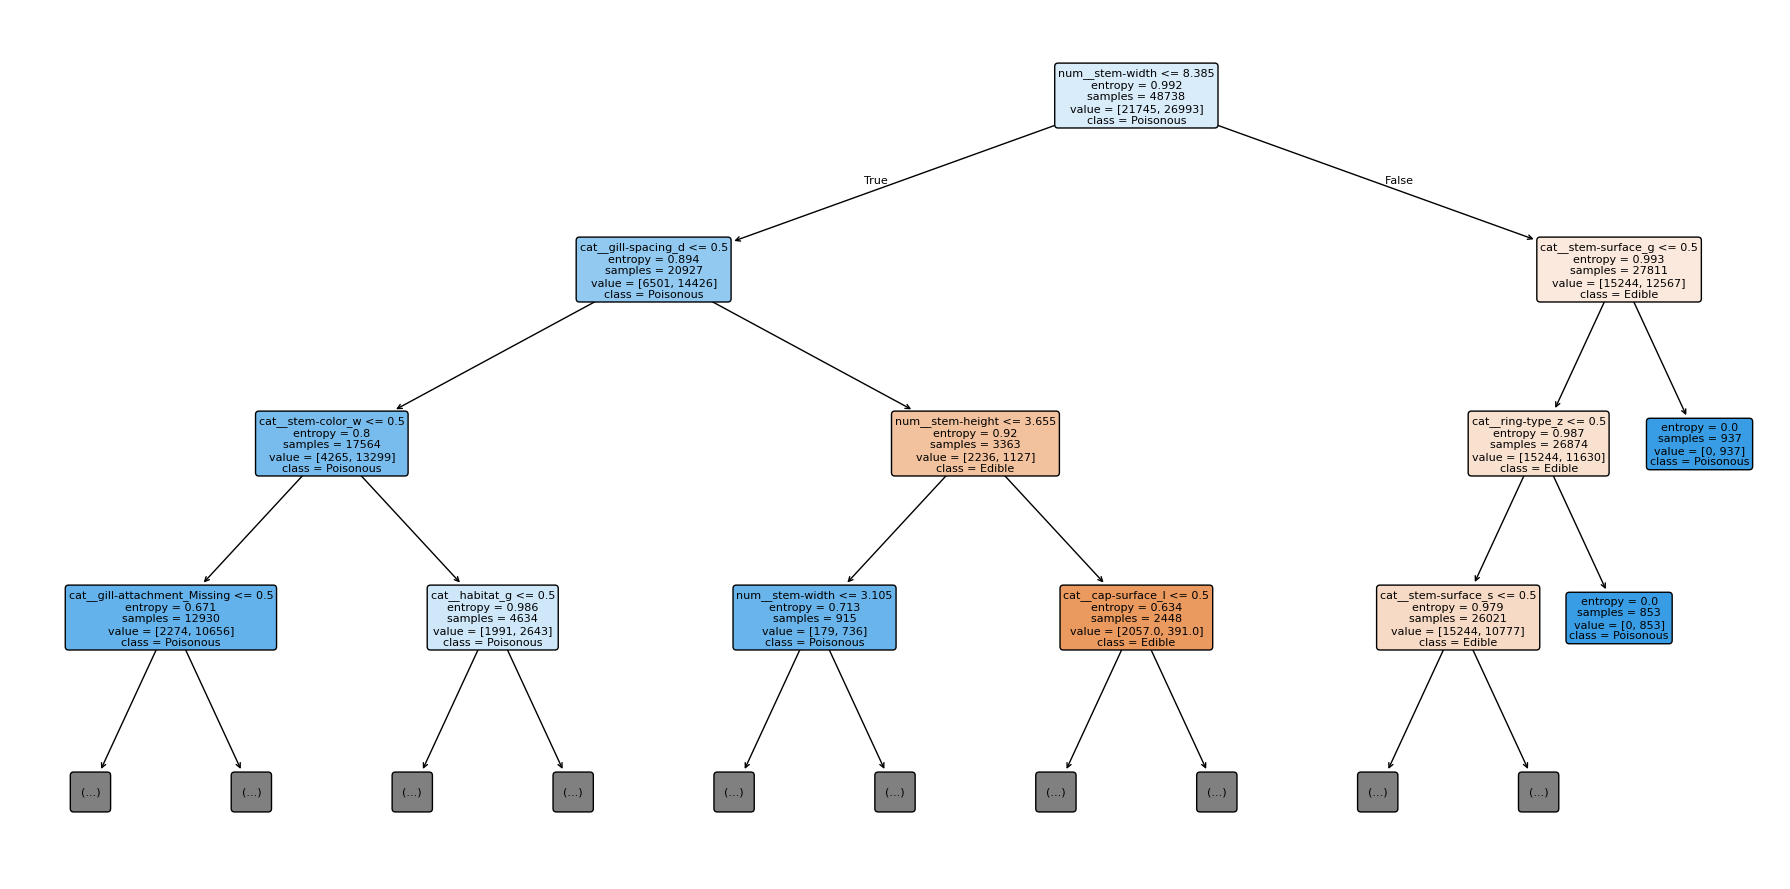

In [28]:
best_tree = models["Decision Tree"]
classifier = best_tree.named_steps["classifier"]
plt.figure(figsize=(18,9))
plot_tree(classifier, feature_names=best_tree.named_steps["preprocess"].get_feature_names_out(),
          class_names=[{"e":"Edible","p":"Poisonous"}[x] for x in classifier.classes_],
          filled=True, rounded=True, max_depth=3, fontsize=8)
savefig("16_tree_diagram")

### 13.2 Permutation importance (optional)
Shuffle one original feature at a time and measure how much F2 decreases. Compare this with mutual information. The two measures have different units; compare their rankings. Use test importance only to explain results, not to change the model.

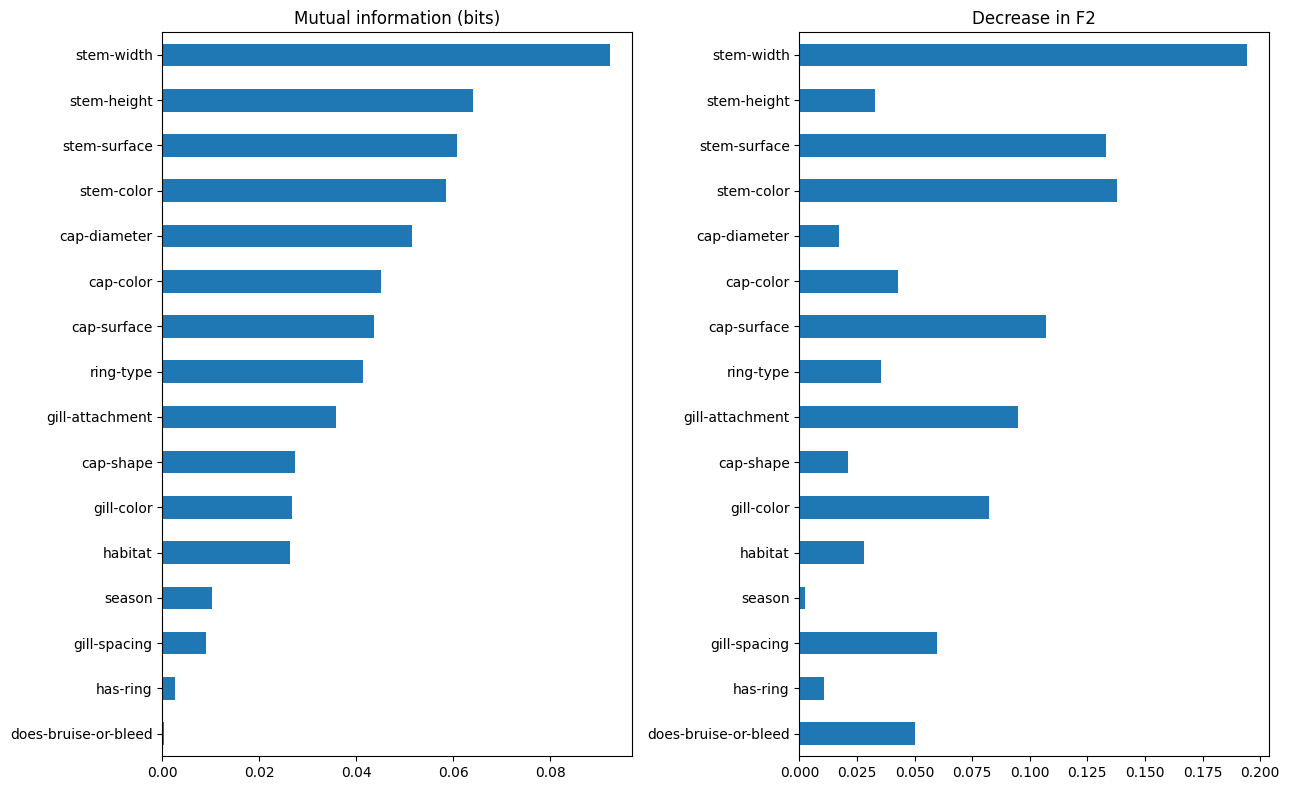

,MI,Permutation importance
cap-color,0.045086,0.042726
cap-diameter,0.051556,0.017335
cap-shape,0.027279,0.021019
cap-surface,0.043601,0.106854
does-bruise-or-bleed,0.000267,0.050209
gill-attachment,0.035838,0.094764
gill-color,0.026700,0.082396
gill-spacing,0.009052,0.059667
habitat,0.026282,0.028137
has-ring,0.002490,0.010603


In [29]:
imp=permutation_importance(models['Decision Tree'],X_test,y_test,scoring=make_scorer(fbeta_score,beta=2,pos_label='p',zero_division=0),n_repeats=5,random_state=SEED,n_jobs=1)
perm=pd.Series(imp.importances_mean,index=X_test.columns); order=mi_ranking.sort_values().index
fig,axes=plt.subplots(1,2,figsize=(13,8)); mi_ranking.loc[order].plot.barh(ax=axes[0]); perm.loc[order].plot.barh(ax=axes[1]); axes[0].set_title('Mutual information (bits)'); axes[1].set_title('Decrease in F2'); savefig('17_importance_comparison')
table(pd.DataFrame({'MI':mi_ranking,'Permutation importance':perm}),'feature_importance')